<a href="https://colab.research.google.com/github/laurenesilver/laurenesilver/blob/main/COMP4009_Term_Project_Gradient_Descent_in_Action.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradient Descent in Action
**COMP 4009: Essential Math for Data Science and AI — Term Project (Optional Code Section)**

This notebook implements gradient descent for linear regression from scratch using NumPy, following the derivations in the written report. It checks the implementation against hand calculations, the normal equation, and scikit-learn, and shows the effect of the learning rate.

## 1. Data and the design matrix
The running example uses four data points: $x = [1, 2, 3, 4]$ and $y = [2, 3, 5, 6]$. The design matrix $X$ puts a column of ones next to the $x$ values, so that $X\theta$ produces every prediction $\theta_0 + \theta_1 x_i$ at once (Report, Section 3).

In [ ]:
import numpy as np

# Running example data
x = np.array([1, 2, 3, 4])
y = np.array([2, 3, 5, 6])
n = len(y)

# Design matrix: a column of ones next to the x values
X = np.column_stack([np.ones(n), x])
print(X)

[[1. 1.]
 [1. 2.]
 [1. 3.]
 [1. 4.]]


## 2. Cost and gradient functions
These implement the matrix-form formulas from the report:
- Cost: $J(\theta) = \frac{1}{2n}(X\theta - y)^T(X\theta - y)$
- Gradient: $\nabla J(\theta) = \frac{1}{n}X^T(X\theta - y)$

The printed values should match the hand calculations: $J(0,0) = 9.25$, $J(0.5, 1.4) = 0.025$, and $\nabla J(0,0) = (-4, -11.75)$.

In [ ]:
def cost(theta, X, y):
    """Mean squared error cost: J = (1/2n) * sum of squared residuals."""
    n = len(y)
    residuals = X @ theta - y
    return (residuals @ residuals) / (2 * n)

def gradient(theta, X, y):
    """Gradient of the cost: (1/n) * X^T (X theta - y)."""
    n = len(y)
    return X.T @ (X @ theta - y) / n

# Check against the numbers from the write-up
theta = np.array([0.0, 0.0])
print(cost(theta, X, y))                   # expect 9.25
print(cost(np.array([0.5, 1.4]), X, y))    # expect 0.025
print(gradient(theta, X, y))               # expect [-4, -11.75]

9.25
0.025000000000000033
[ -4.   -11.75]


## 3. The gradient descent algorithm
Starting from $\theta = 0$, the algorithm repeatedly applies the update rule

$$\theta \leftarrow \theta - \alpha \cdot \frac{1}{n}X^T(X\theta - y)$$

It stops when $\|\nabla J\| < 10^{-6}$ (converged) or after a maximum number of iterations (a safety net in case it never converges).

In [ ]:
def gradient_descent(X, y, alpha, tol=1e-6, max_iters=10000):
    """Run gradient descent on the linear regression cost.

    Stops when the gradient's length falls below tol (converged)
    or after max_iters steps (safety net).
    Returns the final theta, the cost at every iteration,
    and the number of updates taken.
    """
    theta = np.zeros(X.shape[1])   # Step 1: start at theta = 0
    cost_history = []              # empty list to record J each iteration

    for i in range(max_iters):
        cost_history.append(cost(theta, X, y))  # record the current error
        g = gradient(theta, X, y)               # Step 2: compute the gradient
        if np.linalg.norm(g) < tol:             # converged? then stop
            break
        theta = theta - alpha * g               # Step 3: update rule

    return theta, cost_history, i

## 4. Running gradient descent
With learning rate $\alpha = 0.1$, the algorithm converges in 539 iterations to $\theta \approx (0.5, 1.4)$, the best-fit line $y = 0.5 + 1.4x$. The first few costs (9.25, 0.276, 0.032, 0.025) match the iteration table in Section 4 of the report.

In [ ]:
theta, costs, iters = gradient_descent(X, y, alpha=0.1)

print("theta:", theta)
print("iterations:", iters)
print("first costs:", np.round(costs[:4], 4))
print("final cost:", costs[-1])

theta: [0.49999371 1.40000214]
iterations: 539
first costs: [9.25   0.2761 0.0319 0.0252]
final cost: 0.02500000000330834


## 5. Comparison with scikit-learn and the normal equation
Three independent methods should give the same parameters: our gradient descent, scikit-learn's `LinearRegression`, and solving the normal equation $X^TX\theta = X^Ty$ directly. Gradient descent differs only around the sixth decimal place, because it stops once it is *close enough* to the minimum rather than landing on it exactly.

In [ ]:
from sklearn.linear_model import LinearRegression

# Fit scikit-learn's linear regression to the same data
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)

print("sklearn intercept:", model.intercept_)
print("sklearn slope:", model.coef_[0])
print("gradient descent:", theta)

# Bonus: solve the normal equation from Section 3 directly
print("normal equation:", np.linalg.solve(X.T @ X, X.T @ y))

# Do the answers agree (within 0.0001)?
sklearn_theta = np.array([model.intercept_, model.coef_[0]])
print("match:", np.allclose(theta, sklearn_theta, atol=1e-4))

sklearn intercept: 0.5
sklearn slope: 1.4
gradient descent: [0.49999371 1.40000214]
normal equation: [0.5 1.4]
match: True


## 6. The effect of the learning rate
Cost over 50 iterations for three learning rates, on a log scale:
- $\alpha = 0.01$ (too small): the cost falls, but slowly.
- $\alpha = 0.1$ (good): the cost drops quickly and settles at the minimum.
- $\alpha = 0.25$ (too large): each step overshoots the minimum, so the cost grows instead of shrinking. This is divergence (Report, Section 5).

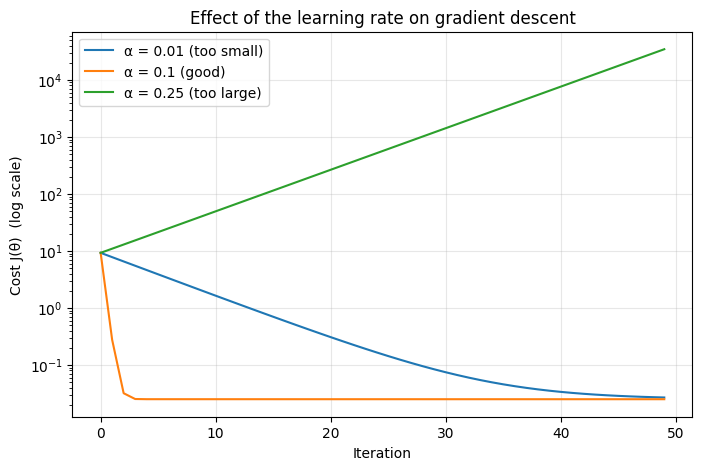

In [ ]:
import matplotlib.pyplot as plt

learning_rates = [0.01, 0.1, 0.25]
labels = ["α = 0.01 (too small)", "α = 0.1 (good)", "α = 0.25 (too large)"]

plt.figure(figsize=(8, 5))

# Run gradient descent for 50 steps at each learning rate and plot the cost
for alpha, label in zip(learning_rates, labels):
    _, history, _ = gradient_descent(X, y, alpha, max_iters=50)
    plt.plot(history, label=label)

plt.yscale("log")   # log scale so tiny and huge costs fit on one plot
plt.xlabel("Iteration")
plt.ylabel("Cost J(θ)  (log scale)")
plt.title("Effect of the learning rate on gradient descent")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. The fitted line
The data points with the line found by gradient descent, $y = 0.5 + 1.4x$.

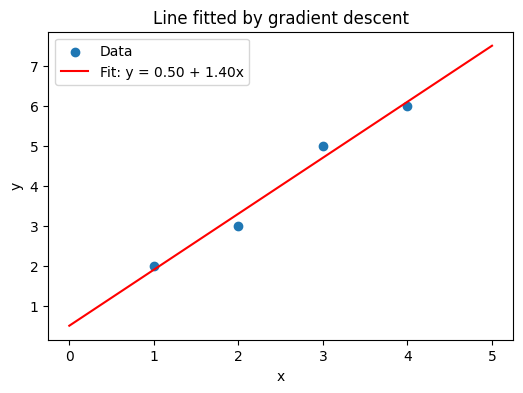

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, label="Data")

# Draw the line y = theta0 + theta1 * x across the range of the data
x_line = np.linspace(0, 5, 100)
plt.plot(x_line, theta[0] + theta[1] * x_line, color="red",
         label=f"Fit: y = {theta[0]:.2f} + {theta[1]:.2f}x")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Line fitted by gradient descent")
plt.legend()
plt.show()

## 8. Automated tests
Six checks confirm the code is correct:
1. The cost matches the hand calculations.
2. The gradient matches Section 3 and equals zero at the minimum.
3. Gradient descent matches scikit-learn on the running example.
4. With a good learning rate, the cost never increases.
5. A too-large learning rate ($\alpha = 0.25$) diverges.
6. The matrix form works with three features, not just one, and still matches scikit-learn.

In [ ]:
def run_tests():
    """Automatic checks that the gradient descent code is correct."""

    # Test 1: cost matches the hand calculations from Section 1
    assert np.isclose(cost(np.array([0.0, 0.0]), X, y), 9.25), "cost at (0, 0) should be 9.25"
    assert np.isclose(cost(np.array([0.5, 1.4]), X, y), 0.025), "cost at best fit should be 0.025"

    # Test 2: gradient matches Section 3, and is zero at the minimum
    assert np.allclose(gradient(np.array([0.0, 0.0]), X, y), [-4, -11.75]), "gradient at (0, 0) is wrong"
    assert np.allclose(gradient(np.array([0.5, 1.4]), X, y), [0, 0]), "gradient should be 0 at the minimum"

    # Test 3: gradient descent matches scikit-learn on the running example
    theta_gd, costs_gd, _ = gradient_descent(X, y, alpha=0.1)
    model = LinearRegression().fit(x.reshape(-1, 1), y)
    assert np.allclose(theta_gd, [model.intercept_, model.coef_[0]], atol=1e-4), "GD does not match sklearn"

    # Test 4: with a good learning rate, the cost never goes up
    assert np.all(np.diff(costs_gd) <= 1e-12), "cost increased during descent"

    # Test 5: a too-large learning rate diverges
    _, costs_big, _ = gradient_descent(X, y, alpha=0.25, max_iters=20)
    assert costs_big[-1] > costs_big[0], "alpha = 0.25 should diverge"

    # Test 6: the matrix form works with several features, not just one
    rng = np.random.default_rng(0)
    features = rng.normal(size=(100, 3))
    target = 2 + features @ np.array([1.5, -3.0, 0.5]) + rng.normal(scale=0.1, size=100)
    X_multi = np.column_stack([np.ones(100), features])
    theta_multi, _, _ = gradient_descent(X_multi, target, alpha=0.1)
    model_multi = LinearRegression().fit(features, target)
    expected = np.concatenate([[model_multi.intercept_], model_multi.coef_])
    assert np.allclose(theta_multi, expected, atol=1e-4), "GD does not match sklearn with 3 features"

    print("All tests passed!")

run_tests()

All tests passed!
